# 02 — Data-quality investigation (Phases 2–3)

**Workflow stages covered:** `06` load & inspect · `07` understand data structure ·
`10` missingness · `11` duplicates, data types, units · `12` outliers & range analysis
(+ re-verification of stage `09` label contract).

**This notebook is read-only.** It never writes to `data/`; figures go to `figures/`,
the verdict goes to `reports/phase2_3_data_quality.md`.

**Contracts inherited from Phase 0 (`reports/phase0_research_definition.md`)**
* label contract — `1` if the danger level is reached in `(t, t+h]`; `0` only if every day in
  that window has ≥3 readings *and* no reach; `NaN` otherwise, never coerced.
* information boundary — `obs_days_*` and any future-derived column may never be a feature.
* raw-data immutability — `data/raw/` is never modified; defects are fixed in code.

**Verification chain:** `scripts/audit_dataset.py` (A1–A10) and `scripts/verify_model_ready.py`
already passed on this dataset; this notebook re-derives the structural facts independently.

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 250)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path("..").resolve()
if not (ROOT / "data").exists():
    ROOT = Path(".").resolve()
FULL_P = ROOT / "data" / "processed" / "flood_dataset.csv"
MR_P   = ROOT / "data" / "processed" / "flood_dataset_model_ready.csv"
DD_P   = ROOT / "data" / "processed" / "data_dictionary.csv"
ST_P   = ROOT / "data" / "raw" / "ffwc" / "ffwc_stations.csv"
FIG    = ROOT / "figures"
FIG.mkdir(exist_ok=True)

checks, findings = [], []

def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if bool(ok) else "FAIL", "detail": str(detail)})
    print(("[PASS] " if ok else "[FAIL] ") + name + (f"  ({detail})" if detail else ""))
    return bool(ok)

def note(tag, text):
    findings.append({"id": tag, "finding": text})
    print(f"[NOTE {tag}] {text}")

def savefig(fig, name):
    p = FIG / name
    fig.savefig(p, bbox_inches="tight")
    print("figure ->", p.relative_to(ROOT))

def mismatches(a, b, tol=1e-6):
    m = a.notna() & b.notna()
    if not m.any():
        return -1, 0
    return int((~np.isclose(a[m].astype(float), b[m].astype(float), atol=tol, rtol=0)).sum()), int(m.sum())

print("root:", ROOT)

root: D:\Flood predictor


---
## PHASE 2 — load and understand the structure (stages 06–07)

In [2]:
full = pd.read_csv(FULL_P, parse_dates=["date"])
mr = pd.read_csv(MR_P, parse_dates=["date"])
master = pd.read_csv(ST_P)

print(f"full matrix : {full.shape[0]:,} rows x {full.shape[1]} cols   "
      f"{full.date.min().date()} .. {full.date.max().date()}")
print(f"model-ready : {mr.shape[0]:,} rows x {mr.shape[1]} cols   "
      f"({100 * len(mr) / len(full):.1f}% of the matrix)")
print(f"stations    : master={len(master)}  in full data={full.station_id.nunique()}  "
      f"modelling={mr.station_id.nunique()}")

check("S06a both files carry the same 54 columns in the same order",
      list(full.columns) == list(mr.columns), f"{full.shape[1]} cols")
keyed = mr.merge(full[["station_id", "date"]], on=["station_id", "date"], how="inner")
check("S06b every model-ready key exists in the full matrix", len(keyed) == len(mr),
      f"{len(keyed):,} keys matched")
check("S06c date is datetime64 and (station_id, date) is unique",
      pd.api.types.is_datetime64_any_dtype(mr.date)
      and int(mr.duplicated(["station_id", "date"]).sum()) == 0)
check("S06d every model-ready row is a fully observed day",
      bool(mr.day_observed.all()), f"{int(mr.day_observed.sum()):,}/{len(mr):,}")

full matrix : 357,250 rows x 54 cols   2017-01-01 .. 2026-10-06
model-ready : 200,665 rows x 54 cols   (56.2% of the matrix)
stations    : master=153  in full data=141  modelling=133
[PASS] S06a both files carry the same 54 columns in the same order  (54 cols)
[PASS] S06b every model-ready key exists in the full matrix  (200,665 keys matched)
[PASS] S06c date is datetime64 and (station_id, date) is unique
[PASS] S06d every model-ready row is a fully observed day  (200,665/200,665)


True

In [3]:
GROUPS = {
    "key":            ["station_id", "date"],
    "identity":       ["name", "river", "basin", "division", "district", "upazilla", "lat", "lon"],
    "threshold":      ["danger_level"],
    "observations":   ["n_readings", "day_observed", "wl_mean", "wl_max", "wl_min", "wl_first", "wl_last"],
    "lags":           [f"wl_last_lag{i}" for i in range(1, 8)] + [f"wl_max_lag{i}" for i in range(1, 4)],
    "derived":        ["wl_rise_1d", "wl_rise_3d", "wl_dist_to_danger", "wl_pct_danger",
                       "wl_max_roll7", "wl_max_roll30", "wl_exceed_days_30"],
    "weather":        ["precip_mm", "rain_1d", "rain_3d", "rain_7d", "rain_14d", "rain_30d",
                       "rain_max_7d", "wet_days_7", "tmax_c", "tmin_c", "source"],
    "seasonality":    ["doy_sin", "doy_cos"],
    "target":         ["label_24h", "label_48h", "label_72h"],
    "banned_feature": ["obs_days_24h", "obs_days_48h", "obs_days_72h"],
}
assigned = [c for v in GROUPS.values() for c in v]
check("S07a every column belongs to exactly one documented group",
      sorted(assigned) == sorted(mr.columns) and len(assigned) == len(set(assigned)),
      f"{len(assigned)} assigned / {mr.shape[1]} present")
for k, v in GROUPS.items():
    print(f"  {k:<14} {len(v):>2}  {', '.join(v[:6])}{' ...' if len(v) > 6 else ''}")

dd = pd.read_csv(DD_P)
print(f"\ndata_dictionary.csv: {len(dd)} grouped entries covering the same columns")

[PASS] S07a every column belongs to exactly one documented group  (54 assigned / 54 present)
  key             2  station_id, date
  identity        8  name, river, basin, division, district, upazilla ...
  threshold       1  danger_level
  observations    7  n_readings, day_observed, wl_mean, wl_max, wl_min, wl_first ...
  lags           10  wl_last_lag1, wl_last_lag2, wl_last_lag3, wl_last_lag4, wl_last_lag5, wl_last_lag6 ...
  derived         7  wl_rise_1d, wl_rise_3d, wl_dist_to_danger, wl_pct_danger, wl_max_roll7, wl_max_roll30 ...
  weather        11  precip_mm, rain_1d, rain_3d, rain_7d, rain_14d, rain_30d ...
  seasonality     2  doy_sin, doy_cos
  target          3  label_24h, label_48h, label_72h
  banned_feature  3  obs_days_24h, obs_days_48h, obs_days_72h

data_dictionary.csv: 14 grouped entries covering the same columns


In [4]:
str_cols = [c for c in mr.columns
            if not pd.api.types.is_numeric_dtype(mr[c])
            and not pd.api.types.is_datetime64_any_dtype(mr[c])]
info = pd.DataFrame({"dtype": mr.dtypes.astype(str),
                     "n_unique": mr.nunique(dropna=True),
                     "missing_%": (100 * mr.isna().mean()).round(2)})
print(info.to_string())
print("\ntext columns:", str_cols)
print("constant columns in model-ready:",
      [c for c in mr.columns if mr[c].nunique(dropna=True) <= 1])

                            dtype  n_unique  missing_%
station_id                  int64       133       0.00
name                          str       133       0.00
river                         str        80       0.00
basin                         str         5       0.00
division                      str         9       0.00
district                      str        55       0.00
upazilla                      str       115       0.16
lat                       float64       133       0.00
lon                       float64       133       0.00
danger_level              float64       103       0.00
date               datetime64[us]      2479       0.00
n_readings                  int64        22       0.00
day_observed                 bool         1       0.00
wl_mean                   float64     28951       0.00
wl_max                    float64      4549       0.00
wl_min                    float64      4637       0.00
wl_first                  float64      4673       0.00
wl_last   

constant columns in model-ready: ['day_observed', 'source']


In [5]:
tab = (full.groupby(full.date.dt.year)
           .agg(rows=("date", "size"), observed_days=("day_observed", "sum"),
                readings=("n_readings", "sum")))
tab["observed_%"] = (100 * tab.observed_days / tab.rows).round(1)
print("full matrix by year")
print(tab.to_string())
print("\nper-station rows (model-ready):")
print(mr.groupby("station_id").size().describe().round(1).to_string())
print("\nhead / tail of the modelling table")
print(mr.head(2).to_string(index=False))
print(mr.tail(2).to_string(index=False))

full matrix by year
       rows  observed_days  readings  observed_%
date                                            
2017  25678          18076     89342        70.4
2018  31390              0         0         0.0
2019  31390          18788     92448        59.9
2020  33382          20591    100851        61.7
2021  37057          22295    108785        60.2
2022  38690          22613    111357        58.4
2023  39191          24767    117254        63.2
2024  40105          25635    123408        63.9
2025  43814          29409    153302        67.1
2026  36553          26151    130581        71.5

per-station rows (model-ready):
count     133.0
mean     1508.8
std       740.5
min        66.0
25%      1139.0
50%      1824.0
75%      2030.0
max      2461.0

head / tail of the modelling table
 station_id     name      river   basin   division    district upazilla       lat       lon  danger_level       date  n_readings  day_observed  wl_mean  wl_max  wl_min  wl_first  wl_last  wl_last

In [6]:
rows = []
for c in ["label_24h", "label_48h", "label_72h"]:
    s = mr[c]
    n, pos = int(s.notna().sum()), int(s.sum())
    rows.append({"target": c, "labelled": n, "positives": pos, "nan": int(s.isna().sum()),
                 "base_rate_%": round(100 * pos / n, 2), "imbalance": round((n - pos) / pos, 1)})
targets = pd.DataFrame(rows)
print(targets.to_string(index=False))
check("S09a labelled rows shrink as the horizon grows",
      targets.labelled.is_monotonic_decreasing,
      f"{targets.labelled.tolist()}")
check("S09b base rate rises with the horizon (longer window, more chance of a reach)",
      targets["base_rate_%"].is_monotonic_increasing,
      f"{targets['base_rate_%'].tolist()}%")
print("\npositives per year (drift is quantified in the last section)")
print(mr.assign(year=mr.date.dt.year).groupby("year")["label_72h"].agg(["count", "sum"]).to_string())

   target  labelled  positives  nan  base_rate_%  imbalance
label_24h    200559       9982  106         4.98       19.1
label_48h    197748      11241 2917         5.68       16.6
label_72h    195174      12340 5491         6.32       14.8
[PASS] S09a labelled rows shrink as the horizon grows  ([200559, 197748, 195174])
[PASS] S09b base rate rises with the horizon (longer window, more chance of a reach)  ([4.98, 5.68, 6.32]%)

positives per year (drift is quantified in the last section)
      count     sum
year               
2017  16838  2831.0
2019  17744  1148.0
2020  19523  3090.0
2021  21140  1759.0
2022  21363  1418.0
2023  23093   275.0
2024  23354   861.0
2025  27837   497.0
2026  24282   461.0


---
## PHASE 3 — missingness (stage 10)

Regression guard first: finding **F1** (NASA POWER `-999` sentinel) was fixed in the rebuild.

In [7]:
SENT = [c for c in ["precip_mm", "tmax_c", "tmin_c", "tmean_c"] if c in full.columns]
RAIN = ["precip_mm", "rain_1d", "rain_3d", "rain_7d", "rain_14d", "rain_30d", "rain_max_7d"]

n_sent_full = sum(int((full[c] <= -999).sum()) for c in SENT)
n_sent_mr = sum(int((mr[c] <= -999).sum()) for c in SENT)
n_neg = sum(int((full[c] < 0).sum()) for c in RAIN)
check("Q10a no NASA POWER sentinel value survives anywhere (<= -999)",
      n_sent_full == 0 and n_sent_mr == 0, f"full={n_sent_full}, model-ready={n_sent_mr}")
check("Q10b no negative rainfall in any window column", n_neg == 0, f"{n_neg} cells")

dts = sorted(full.loc[full.precip_mm.isna(), "date"].dt.strftime("%Y-%m-%d").unique())
check("Q10c remaining weather NaN confined to the F1 window 2026-10-04..06",
      set(dts) <= {"2026-10-04", "2026-10-05", "2026-10-06"},
      f"{len(dts)} dates, {int(full.precip_mm.isna().sum())} full-matrix rows, "
      f"{int(mr.precip_mm.isna().sum())} model-ready rows")
note("G2", f"{int(mr.precip_mm.isna().sum())} model-ready rows have NaN weather "
            "(F1 residual, days not yet published) -> the logistic-regression baseline needs a "
            "median imputer fitted inside the training fold; LightGBM/XGBoost take NaN natively")

[PASS] Q10a no NASA POWER sentinel value survives anywhere (<= -999)  (full=0, model-ready=0)
[PASS] Q10b no negative rainfall in any window column  (0 cells)
[PASS] Q10c remaining weather NaN confined to the F1 window 2026-10-04..06  (3 dates, 381 full-matrix rows, 244 model-ready rows)
[NOTE G2] 244 model-ready rows have NaN weather (F1 residual, days not yet published) -> the logistic-regression baseline needs a median imputer fitted inside the training fold; LightGBM/XGBoost take NaN natively


model-ready: 22 columns with missing values
wl_max_roll30    3.53
wl_last_lag7     3.37
wl_last_lag6     2.91
label_72h        2.74
wl_last_lag5     2.44
wl_last_lag4     2.01
wl_rise_3d       1.62
wl_max_lag3      1.62
wl_last_lag3     1.62
label_48h        1.45
wl_max_roll7     1.27
wl_max_lag2      1.18
wl_last_lag2     1.18
wl_last_lag1     0.50
wl_rise_1d       0.50
wl_max_lag1      0.50
upazilla         0.16
precip_mm        0.12
tmax_c           0.12
rain_1d          0.12
tmin_c           0.12
label_24h        0.05

full matrix: 31 columns with missing values (top 25)
label_72h            44.59
label_48h            43.81
label_24h            42.91
wl_rise_3d           42.03
wl_pct_danger        41.68
wl_dist_to_danger    41.68
wl_rise_1d           41.13
wl_last_lag7         40.74
wl_last_lag6         40.70
wl_max_roll7         40.67
wl_last_lag5         40.66
wl_last_lag4         40.62
wl_last_lag3         40.58
wl_max_lag3          40.58
wl_last_lag2         40.54
wl_max_lag2  

figure -> figures\phase23_missingness.png


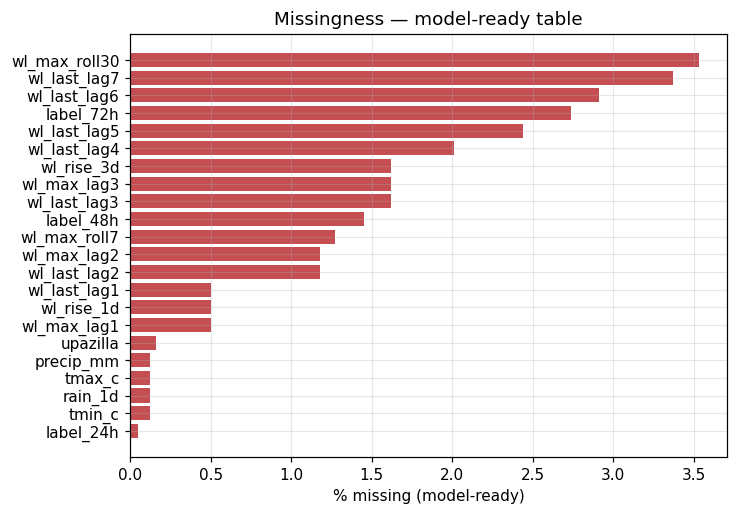

In [8]:
def miss(df):
    m = (100 * df.isna().mean()).round(2)
    return m[m > 0].sort_values(ascending=False)

mm, mf = miss(mr), miss(full)
print(f"model-ready: {len(mm)} columns with missing values")
print(mm.to_string())
print(f"\nfull matrix: {len(mf)} columns with missing values (top 25)")
print(mf.head(25).to_string())

LAGS = [f"wl_last_lag{i}" for i in range(1, 8)] + [f"wl_max_lag{i}" for i in range(1, 4)]
EXPECTED = set(LAGS) | {"wl_rise_1d", "wl_rise_3d", "wl_max_roll7", "wl_max_roll30",
                        "label_24h", "label_48h", "label_72h",
                        "precip_mm", "rain_1d", "tmax_c", "tmin_c", "upazilla"}
check("Q10d model-ready missingness confined to documented columns",
      set(mm.index) <= EXPECTED, f"unexpected: {sorted(set(mm.index) - EXPECTED)}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(mm.index[::-1], mm.values[::-1], color="#c44e52")
ax.set_xlabel("% missing (model-ready)")
ax.set_title("Missingness — model-ready table")
savefig(fig, "phase23_missingness.png")

In [9]:
print("label NaN decomposition: a label is NaN only when its window is incomplete")
for h, d in [(24, 1), (48, 2), (72, 3)]:
    lab, ob = mr[f"label_{h}h"], mr[f"obs_days_{h}h"]
    viol0 = int(((lab == 0) & (ob < d)).sum())          # a 0 must have a complete window
    nan_full = int((lab.isna() & (ob >= d)).sum())       # a complete window must have a label
    partial_pos = int(((lab == 1) & (ob < d)).sum())     # legal: reach observed on a partial window
    check(f"S09c label contract {h}h — no 0 on an incomplete window", viol0 == 0, f"{viol0} violations")
    check(f"S09d label contract {h}h — no NaN on a complete window", nan_full == 0, f"{nan_full} rows")
    print(f"        {h}h: NaN={int(lab.isna().sum()):,}  "
          f"proved-reach on a partial window={partial_pos:,}")
print("\ncrosstab obs_days_72h x label_72h")
print(pd.crosstab(mr.obs_days_72h, mr.label_72h, dropna=False).to_string())

label NaN decomposition: a label is NaN only when its window is incomplete
[PASS] S09c label contract 24h — no 0 on an incomplete window  (0 violations)
[PASS] S09d label contract 24h — no NaN on a complete window  (0 rows)
        24h: NaN=106  proved-reach on a partial window=0
[PASS] S09c label contract 48h — no 0 on an incomplete window  (0 violations)
[PASS] S09d label contract 48h — no NaN on a complete window  (0 rows)
        48h: NaN=2,917  proved-reach on a partial window=175
[PASS] S09c label contract 72h — no 0 on an incomplete window  (0 violations)
[PASS] S09d label contract 72h — no NaN on a complete window  (0 rows)
        72h: NaN=5,491  proved-reach on a partial window=321

crosstab obs_days_72h x label_72h
label_72h        0.0    1.0   NaN
obs_days_72h                     
1                  0     54  1857
2                  0    267  3634
3             182834  12019     0


---
## PHASE 3 — duplicates, data types, units (stage 11)

In [10]:
check("Q11a no exact duplicate rows",
      int(full.duplicated().sum()) == 0 and int(mr.duplicated().sum()) == 0,
      f"full={int(full.duplicated().sum())}, model-ready={int(mr.duplicated().sum())}")
check("Q11b no duplicate (station_id, date) keys",
      int(full.duplicated(['station_id', 'date']).sum()) == 0
      and int(mr.duplicated(['station_id', 'date']).sum()) == 0)
mono = mr.sort_values(["station_id", "date"]).groupby("station_id")["date"].is_monotonic_increasing
check("Q11c dates strictly increase within every station", bool(mono.all()),
      f"{int((~mono).sum())} stations broken")
check("Q11d model-ready station ids all exist in the FFWC master list",
      set(mr.station_id) <= set(master.id), f"{len(set(mr.station_id) - set(master.id))} unknown")

[PASS] Q11a no exact duplicate rows  (full=0, model-ready=0)
[PASS] Q11b no duplicate (station_id, date) keys
[PASS] Q11c dates strictly increase within every station  (0 stations broken)
[PASS] Q11d model-ready station ids all exist in the FFWC master list  (0 unknown)


True

In [11]:
lab_cols = ["label_24h", "label_48h", "label_72h"]
check("Q12a labels contain only 0 / 1 / NaN",
      all(bool(mr[c].dropna().isin([0, 1]).all()) for c in lab_cols))
check("Q12b doy_sin / doy_cos lie on the unit circle",
      float((np.hypot(mr.doy_sin, mr.doy_cos) - 1).abs().max()) < 1e-9,
      f"max err {float((np.hypot(mr.doy_sin, mr.doy_cos) - 1).abs().max()):.2e}")
check("Q12c wet_days_7 is an integer count in 0..7",
      bool((mr.wet_days_7.dropna() % 1 == 0).all())
      and mr.wet_days_7.dropna().between(0, 7).all())
check("Q12d obs_days_* within 0..h days",
      bool(mr.obs_days_24h.between(0, 1).all() and mr.obs_days_48h.between(0, 2).all()
           and mr.obs_days_72h.between(0, 3).all()))

bad_t = int((mr.tmin_c.notna() & mr.tmax_c.notna() & ~(mr.tmin_c <= mr.tmax_c)).sum())
check("Q12e tmin_c <= tmax_c everywhere", bad_t == 0, f"{bad_t} violations")
m = mr.wl_min.notna() & mr.wl_mean.notna() & mr.wl_max.notna()
bad_w = int((~((mr.wl_min[m] <= mr.wl_mean[m] + 1e-9) & (mr.wl_mean[m] <= mr.wl_max[m] + 1e-9))).sum())
check("Q12f wl_min <= wl_mean <= wl_max (float tolerance 1e-9)", bad_w == 0, f"{bad_w} violations")
a = mr[["rain_1d", "rain_3d", "rain_7d", "rain_30d"]].dropna()
mono_rain = (a.rain_1d <= a.rain_3d + 1e-9) & (a.rain_3d <= a.rain_7d + 1e-9)             & (a.rain_7d <= a.rain_30d + 1e-9)
check("Q12g rain windows never decrease as the window widens (tol 1e-9)",
      bool(mono_rain.all()), f"{int((~mono_rain).sum())} of {len(a):,} rows")
check("Q12h lat/lon inside the Bangladesh bounding box",
      bool(mr.lat.between(20.5, 26.8).all() and mr.lon.between(88.0, 92.8).all()),
      f"lat {mr.lat.min():.3f}..{mr.lat.max():.3f}, lon {mr.lon.min():.3f}..{mr.lon.max():.3f}")
check("Q12i danger_level strictly positive", bool((mr.danger_level > 0).all()),
      f"{int((mr.danger_level <= 0).sum())} non-positive")
check("Q12j weather source recorded for every row",
      bool(mr.source.notna().all() and mr.source.nunique() == 1),
      f"{mr.source.nunique()} distinct source value(s)")

[PASS] Q12a labels contain only 0 / 1 / NaN
[PASS] Q12b doy_sin / doy_cos lie on the unit circle  (max err 2.22e-16)
[PASS] Q12c wet_days_7 is an integer count in 0..7
[PASS] Q12d obs_days_* within 0..h days
[PASS] Q12e tmin_c <= tmax_c everywhere  (0 violations)
[PASS] Q12f wl_min <= wl_mean <= wl_max (float tolerance 1e-9)  (0 violations)
[PASS] Q12g rain windows never decrease as the window widens (tol 1e-9)  (0 of 200,421 rows)
[PASS] Q12h lat/lon inside the Bangladesh bounding box  (lat 21.774..26.330, lon 88.069..92.486)
[PASS] Q12i danger_level strictly positive  (0 non-positive)
[PASS] Q12j weather source recorded for every row  (1 distinct source value(s))


True

In [12]:
print("derived-column identities (they must be recomputable from their inputs)")
n, t = mismatches(mr.wl_rise_1d, mr.wl_last - mr.wl_last_lag1, 1e-9)
check("S07b wl_rise_1d == wl_last - wl_last_lag1", n == 0, f"{n} mismatches of {t}")
n, t = mismatches(mr.wl_rise_3d, mr.wl_last - mr.wl_last_lag3, 1e-9)
check("S07c wl_rise_3d == wl_last - wl_last_lag3", n == 0, f"{n} mismatches of {t}")
n, t = mismatches(mr.wl_dist_to_danger, mr.danger_level - mr.wl_max, 1e-9)
check("S07d wl_dist_to_danger == danger_level - wl_max", n == 0, f"{n} mismatches of {t}")
n, t = mismatches(mr.wl_pct_danger, mr.wl_max / mr.danger_level, 1e-9)
check("S07e wl_pct_danger == wl_max / danger_level (a FRACTION, see finding F2)",
      n == 0, f"{n} mismatches of {t}")
note("F2", "wl_pct_danger is stored as a fraction of the danger level (0.61 = 61%), "
           "despite 'pct' in the name -> document as a fraction or rename at Phase 26")

s = full.sort_values(["station_id", "date"])
sh1 = s.groupby("station_id")["wl_last"].shift(1)
n, t = mismatches(s.wl_last_lag1, sh1, 1e-9)
check("S07f wl_last_lag1 == previous calendar day's wl_last", n == 0, f"{n} mismatches of {t}")
n, t = mismatches(s.wl_last_lag3, s.groupby("station_id")["wl_last"].shift(3), 1e-9)
check("S07g wl_last_lag3 == same value three calendar days earlier", n == 0, f"{n} mismatches of {t}")
note("G1", "lags are plain calendar shifts: wl_last_lag1 is NaN whenever the previous calendar "
           "day was unobserved (no last-observation-carried-forward) -> 0.50% of model-ready rows")

derived-column identities (they must be recomputable from their inputs)
[PASS] S07b wl_rise_1d == wl_last - wl_last_lag1  (0 mismatches of 199670)
[PASS] S07c wl_rise_3d == wl_last - wl_last_lag3  (0 mismatches of 197409)
[PASS] S07d wl_dist_to_danger == danger_level - wl_max  (0 mismatches of 200665)
[PASS] S07e wl_pct_danger == wl_max / danger_level (a FRACTION, see finding F2)  (0 mismatches of 200665)
[NOTE F2] wl_pct_danger is stored as a fraction of the danger level (0.61 = 61%), despite 'pct' in the name -> document as a fraction or rename at Phase 26


[PASS] S07f wl_last_lag1 == previous calendar day's wl_last  (0 mismatches of 212556)
[PASS] S07g wl_last_lag3 == same value three calendar days earlier  (0 mismatches of 212276)
[NOTE G1] lags are plain calendar shifts: wl_last_lag1 is NaN whenever the previous calendar day was unobserved (no last-observation-carried-forward) -> 0.50% of model-ready rows


In [13]:
g = s.groupby("station_id")["precip_mm"]
tot = 0
for k in [1, 3, 7, 14, 30]:
    rec = g.transform(lambda x, k=k: x.rolling(k, min_periods=1).sum())
    n, t = mismatches(s[f"rain_{k}d"], rec, 1e-6)
    print(f"  rain_{k}d: {n} mismatches of {t}")
    tot += max(n, 0)
rec = g.transform(lambda x: x.rolling(7, min_periods=1).max())
n, t = mismatches(s.rain_max_7d, rec, 1e-6)
print(f"  rain_max_7d: {n} mismatches of {t}")
tot += max(n, 0)
wet = g.transform(lambda x: (x.fillna(0) > 1.0).rolling(7, min_periods=1).sum())
n, t = mismatches(s.wet_days_7, wet, 1e-6)
print(f"  wet_days_7: {n} mismatches of {t}")
tot += max(n, 0)
check("S07h every rain feature recomputed from calendar-day precipitation matches the stored column",
      tot == 0, f"{tot} mismatches")

  rain_1d: 0 mismatches of 356869


  rain_3d: 0 mismatches of 357123
  rain_7d: 0 mismatches of 357250


  rain_14d: 0 mismatches of 357250
  rain_30d: 0 mismatches of 357250


  rain_max_7d: 0 mismatches of 357250
  wet_days_7: 0 mismatches of 357250
[PASS] S07h every rain feature recomputed from calendar-day precipitation matches the stored column  (0 mismatches)


True

---
## PHASE 3 — outliers, ranges, physical plausibility (stage 12)

In [14]:
cols = ["wl_mean", "wl_max", "wl_dist_to_danger", "wl_pct_danger",
        "rain_1d", "rain_7d", "rain_30d", "tmax_c", "tmin_c"]
print(mr[cols].quantile([0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).round(3).to_string())

spike = full.loc[full.wl_max > 100,
                 ["station_id", "name", "date", "n_readings", "wl_min", "wl_mean",
                  "wl_max", "danger_level"]]
spike_mr = int((mr.wl_max > 100).sum())
check("Q12k no physically impossible water levels survive (F3 rule, > 100 m)",
      len(spike) == 0 and spike_mr == 0,
      f"{len(spike)} matrix rows / {spike_mr} model-ready rows above 100 m")
print(f"max wl_max = {float(full.wl_max.max()):.2f} m  "
      f"(highest published danger level = {full.danger_level.max()} m)")
rise_max = float(mr.wl_rise_1d.abs().max())
check("Q12l no single-reading spikes survived (F8 rule: day-over-day jump bound)",
      rise_max <= 15.0,
      f"max |wl_rise_1d| = {rise_max:.2f} m/day (bound 15 m; real max ~7.8 m)")
note("F3", "FIXED 2026-10-07 (decision D4): 5 decimal-shifted readings >100 m clipped to NaN "
           "at load time - removed 27 false-positive labels and 2 now-unobserved rows; "
           "raw FFWC feed untouched; see reports/phase2_3_data_quality.md")
note("F8", "FIXED 2026-10-07: 21 single-reading sensor spikes (|wl - local 12-h median| "
           "> 10 m) dropped at load time - e.g. Chuadanga 38.84 m beside 3.85 m and "
           "Sheola 33.36 m (both above danger -> false-positive labels), Panchagarh "
           "0.65 m beside 64.75 m, year-boundary 0.00 m codes; see reports/phase2_3_data_quality.md")

neg = int((full.wl_mean < 0).sum())
print(f"\nnegative wl_mean rows: {neg} (stations "
      f"{sorted(full.loc[full.wl_mean < 0, 'station_id'].unique().tolist())})")
note("F4", f"{neg} rows with negative water levels at tidal/coastal stations (Mongla, Dohazari, "
           "Kalapara) - consistent with a below-datum tide, but review at Phase 15 before "
           "treating them as real")
over = int((mr.wl_pct_danger > 1).sum())
note("G4", f"{over:,} model-ready rows sit above the danger level (wl_pct_danger > 1) - "
           "legitimate, these are the positive cases")

       wl_mean  wl_max  wl_dist_to_danger  wl_pct_danger  rain_1d  rain_7d  rain_30d  tmax_c  tmin_c
0.001    0.144    0.35             -1.550          0.065     0.00    0.000     0.000   21.47   8.884
0.010    0.530    0.81             -0.820          0.127     0.00    0.000     0.450   24.61  12.630
0.250    3.352    3.50              1.410          0.531     1.49   32.450   205.770   30.14  23.900
0.500    7.034    7.09              2.850          0.740     6.74   70.550   342.110   31.42  25.570
0.750   13.574   13.63              4.740          0.889    16.82  121.850   490.300   32.74  26.360
0.990   64.536   64.55             10.160          1.127    89.54  423.934  1334.258   40.36  27.820
0.999   67.457   67.53             11.473          1.544   189.04  828.240  2095.410   43.42  28.670
[PASS] Q12k no physically impossible water levels survive (F3 rule, > 100 m)  (0 matrix rows / 0 model-ready rows above 100 m)
max wl_max = 70.81 m  (highest published danger level = 70.3 m)
[

In [15]:
d = full.sort_values(["station_id", "date"])
span = d.groupby("station_id")["date"].agg(lambda x: (x.max() - x.min()).days + 1)
cnt = d.groupby("station_id").size()
check("Q14a every station has exactly one row per calendar day of its lifetime",
      bool((span == cnt).all()), f"{int((span != cnt).sum())} stations with gaps")

yearly = full.groupby(full.date.dt.year).agg(rows=("date", "size"),
                                             observed_days=("day_observed", "sum"),
                                             readings=("n_readings", "sum"))
print(yearly.to_string())
check("Q14b 2018 confirmed as a full-year blackout (0 readings)",
      int(yearly.loc[2018, "readings"]) == 0,
      f"{int(yearly.loc[2018, 'rows']):,} calendar rows, 0 observations")

b = ~d.day_observed.astype(bool)
rid = (b != b.groupby(d.station_id).shift()).cumsum()
run_key = d.station_id.astype(str) + "|" + rid.astype(str)
run_len = b.groupby(run_key).transform("size").where(b, 0)
max_run = run_len.groupby(d.station_id).max()
cov = d.groupby("station_id")["day_observed"].mean()
print(f"coverage: median {100 * cov.median():.1f}%  min {100 * cov.min():.1f}% "
      f"(station {int(cov.idxmin())})")
print(f"longest unobserved run: median {int(max_run.median())} d  p90 {int(max_run.quantile(.9))} d  "
      f"max {int(max_run.max())} d (station {int(max_run.idxmax())})")
print("worst-covered stations:")
print(pd.DataFrame({"coverage_%": (100 * cov).round(1), "longest_gap_d": max_run.astype(int)})
      .sort_values("coverage_%").head(8).to_string())
note("F7", f"median station coverage {100 * cov.median():.0f}% and a median longest unobserved run "
           f"of {int(max_run.median())} days (the 2018 blackout dominates) -> temporal splits must "
           "be built per station-year, never on a single global cut")

[PASS] Q14a every station has exactly one row per calendar day of its lifetime  (0 stations with gaps)


       rows  observed_days  readings
date                                
2017  25678          18076     89342
2018  31390              0         0
2019  31390          18788     92448
2020  33382          20591    100851
2021  37057          22295    108785
2022  38690          22613    111357
2023  39191          24767    117254
2024  40105          25635    123408
2025  43814          29409    153302
2026  36553          26151    130581
[PASS] Q14b 2018 confirmed as a full-year blackout (0 readings)  (31,390 calendar rows, 0 observations)


coverage: median 58.9%  min 17.7% (station 155)
longest unobserved run: median 426 d  p90 521 d  max 620 d (station 39)
worst-covered stations:
            coverage_%  longest_gap_d
station_id                           
155               17.7            311
148               30.0            179
12                43.8            518
39                46.6            620
1                 49.8            518
17                50.6            571
4                 51.2            521
18                51.3            562
[NOTE F7] median station coverage 59% and a median longest unobserved run of 426 days (the 2018 blackout dominates) -> temporal splits must be built per station-year, never on a single global cut


figure -> figures\phase23_coverage.png


figure -> figures\phase23_station_example.png


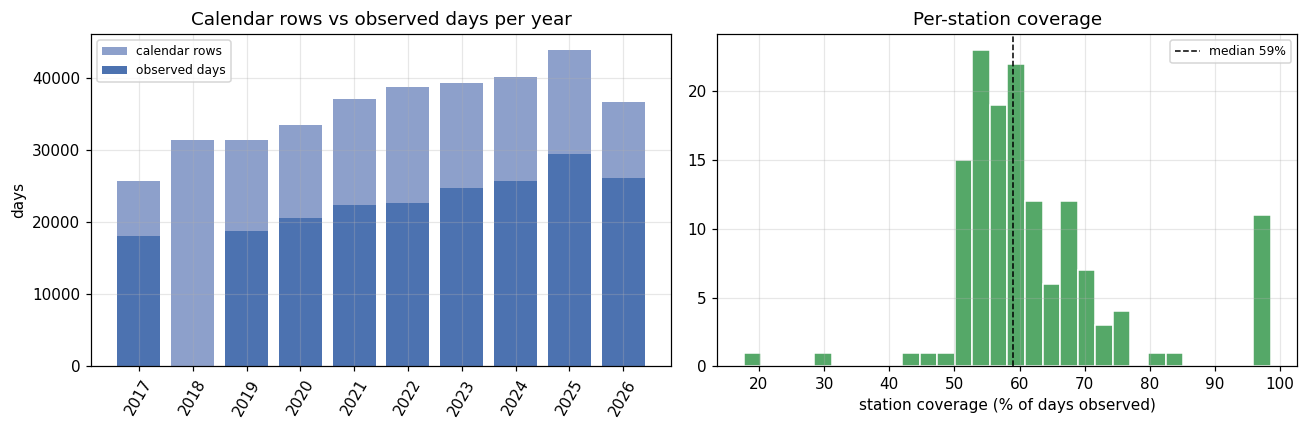

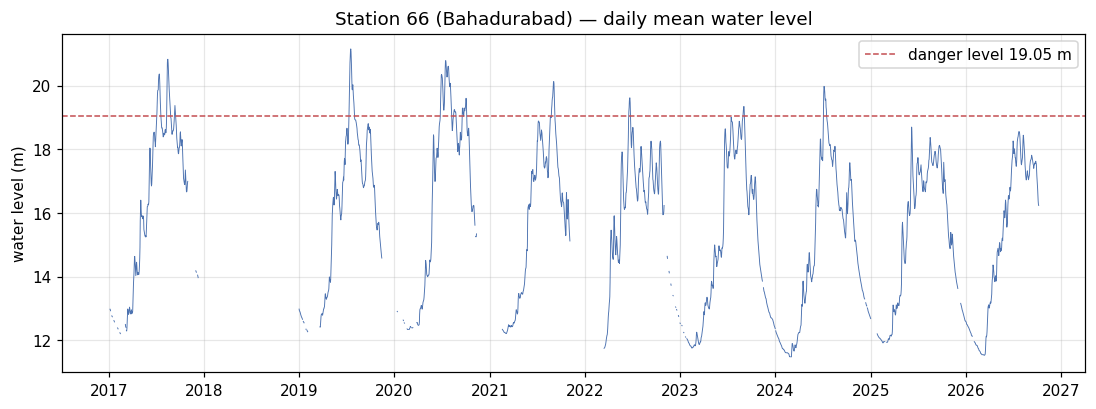

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(yearly.index.astype(str), yearly.rows, color="#8da0cb", label="calendar rows")
axes[0].bar(yearly.index.astype(str), yearly.observed_days, color="#4c72b0", label="observed days")
axes[0].set_title("Calendar rows vs observed days per year")
axes[0].set_ylabel("days")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=60)

axes[1].hist(100 * cov, bins=30, color="#55a868", edgecolor="white")
axes[1].axvline(100 * cov.median(), color="black", ls="--", lw=1,
                label=f"median {100 * cov.median():.0f}%")
axes[1].set_xlabel("station coverage (% of days observed)")
axes[1].set_title("Per-station coverage")
axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "phase23_coverage.png")

sid = int(full.groupby("station_id")["day_observed"].sum().idxmax())
st = full[full.station_id == sid].sort_values("date")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(st.date, st.wl_mean, lw=0.6, color="#4c72b0")
ax.axhline(st.danger_level.iloc[0], color="#c44e52", ls="--", lw=1,
           label=f"danger level {st.danger_level.iloc[0]} m")
ax.set_title(f"Station {sid} ({st.name.iloc[0]}) — daily mean water level")
ax.set_ylabel("water level (m)")
ax.legend()
savefig(fig, "phase23_station_example.png")

---
## Label drift over time (feeds Phase 4 / risk **R1**)

per-year base rate (%)
      label_24h  label_48h  label_72h
year                                 
2017      13.37      15.20      16.81
2019       5.01       5.77       6.47
2020      13.57      14.77      15.83
2021       6.78       7.59       8.32
2022       5.08       5.96       6.64
2023       0.68       0.93       1.19
2024       2.54       3.11       3.69
2025       1.17       1.49       1.79
2026       1.27       1.60       1.90

positives per year
      label_24h  label_48h  label_72h
year                                 
2017       2333       2597       2831
2019        918       1039       1148
2020       2721       2920       3090
2021       1474       1628       1759
2022       1111       1289       1418
2023        162        218        275
2024        619        740        861
2025        330        419        497
2026        314        391        461
figure -> figures\phase23_label_drift.png
[PASS] Q15a drift computed for every year and horizon  (9 years)
[NOTE R1] labe

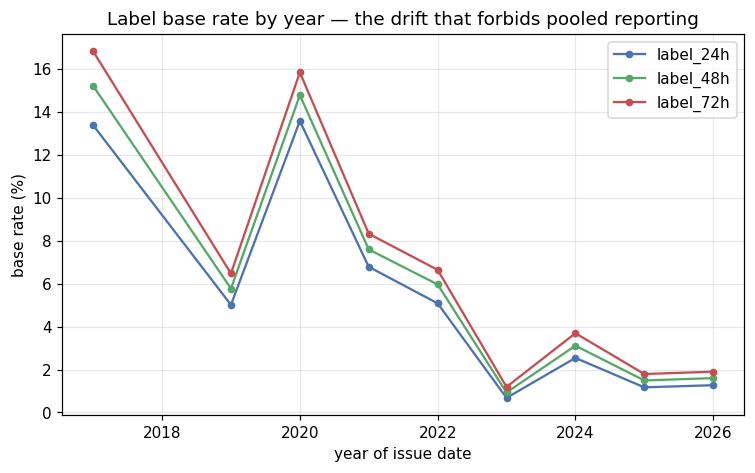

In [17]:
rates = {}
for c in lab_cols:
    g = mr.assign(year=mr.date.dt.year).groupby("year")[c]
    rates[c] = (100 * g.sum() / g.count()).round(2)
piv = pd.DataFrame(rates)
print("per-year base rate (%)")
print(piv.to_string())
print("\npositives per year")
print(mr.assign(year=mr.date.dt.year).groupby("year")[lab_cols].sum().astype(int).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, color in zip(lab_cols, ["#4c72b0", "#55a868", "#c44e52"]):
    ax.plot(piv.index, piv[c], marker="o", ms=4, label=c, color=color)
ax.set_xlabel("year of issue date")
ax.set_ylabel("base rate (%)")
ax.set_title("Label base rate by year — the drift that forbids pooled reporting")
ax.legend()
savefig(fig, "phase23_label_drift.png")

r = piv["label_72h"]
check("Q15a drift computed for every year and horizon", piv.notna().all().all(),
      f"{len(piv)} years")
note("R1", f"label_72h base rate runs {r.min()}% ({int(r.idxmin())}) to {r.max()}% "
           f"({int(r.idxmax())}) -> every Phase 17+ metric must be reported per year, "
           "never pooled across the whole record")

---
## Verdict

In [18]:
res = pd.DataFrame(checks)[["result", "check", "detail"]]
pd.set_option("display.max_colwidth", 95)
print(res.to_string(index=False))
n_fail = int((res.result == "FAIL").sum())
print(f"\n{int((res.result == 'PASS').sum())} PASS / {n_fail} FAIL  |  {len(findings)} findings recorded")
if findings:
    print(pd.DataFrame(findings).to_string(index=False))
print("\nRESULT:", "ALL CHECKS PASSED" if n_fail == 0 else "FAILURES PRESENT - see above")
assert n_fail == 0, f"{n_fail} checks failed"

result                                                                                        check                                                      detail
  PASS                                  S06a both files carry the same 54 columns in the same order                                                     54 cols
  PASS                                         S06b every model-ready key exists in the full matrix                                        200,665 keys matched
  PASS                                     S06c date is datetime64 and (station_id, date) is unique                                                            
  PASS                                           S06d every model-ready row is a fully observed day                                             200,665/200,665
  PASS                                    S07a every column belongs to exactly one documented group                                    54 assigned / 54 present
  PASS                                  